# Домашнє завдання: Прогнозування орендної плати за житло

## Мета завдання
Застосувати знання з лекції для побудови моделі лінійної регресії, що прогнозує орендну плату за житло в Індії. Ви пройдете весь цикл вирішення задачі машинного навчання: від дослідницького аналізу до оцінки якості моделі.

## Опис датасету
**House Rent Prediction Dataset** містить інформацію про 4700+ оголошень про оренду житла в Індії з такими параметрами:
- **BHK**: Кількість спалень, залів, кухонь
- **Rent**: Орендна плата (цільова змінна)
- **Size**: Площа в квадратних футах
- **Floor**: Поверх та загальна кількість поверхів
- **Area Type**: Тип розрахунку площі
- **Area Locality**: Район
- **City**: Місто
- **Furnishing Status**: Стан меблювання
- **Tenant Preferred**: Тип орендаря
- **Bathroom**: Кількість ванних кімнат
- **Point of Contact**: Контактна особа

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `House_Rent_Dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (включно з типами даних та кількістю значень)


In [3]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [4]:
df = pd.read_csv("House_Rent_Dataset.csv")


In [5]:
df.shape


(4746, 12)

In [7]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


## Завдання 2: Дослідницький аналіз даних (EDA) (5 балів)

**Що потрібно зробити:**
1. **Аналіз пропущених значень.** Перевірте наявність і відсоток пропущених значень у кожній колонці
2. **Базова статистика.** Обчисліть базову статистику (середнє, квартилі, стандартне відхилення) для числових змінних.
3. **Аналіз цільової змінної.** Побудуйте гістограму розподілу цільової змінної (Rent)
4. **Робота з викидами.** Знайдіть та видаліть викиди в цільовій змінній (якщо є). Визначити викиди можна будь-яким зрозумілим для вас способом, як варіант - таким, що використовується в побудові box-plot (https://en.wikipedia.org/wiki/Box_plot#Example_with_outliers).
5. **Аналіз категоріальних змінних.** Виведіть кількість унікальних значень для кожної з категоріальних колонок.


In [9]:
df.isna().mean() * 100

Posted On            0.0
BHK                  0.0
Rent                 0.0
Size                 0.0
Floor                0.0
Area Type            0.0
Area Locality        0.0
City                 0.0
Furnishing Status    0.0
Tenant Preferred     0.0
Bathroom             0.0
Point of Contact     0.0
dtype: float64

In [10]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.746000e+03,4746.000000,4746.000000
mean,2.083860,3.499345e+04,967.490729,1.965866
std,0.832256,7.810641e+04,634.202328,0.884532
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


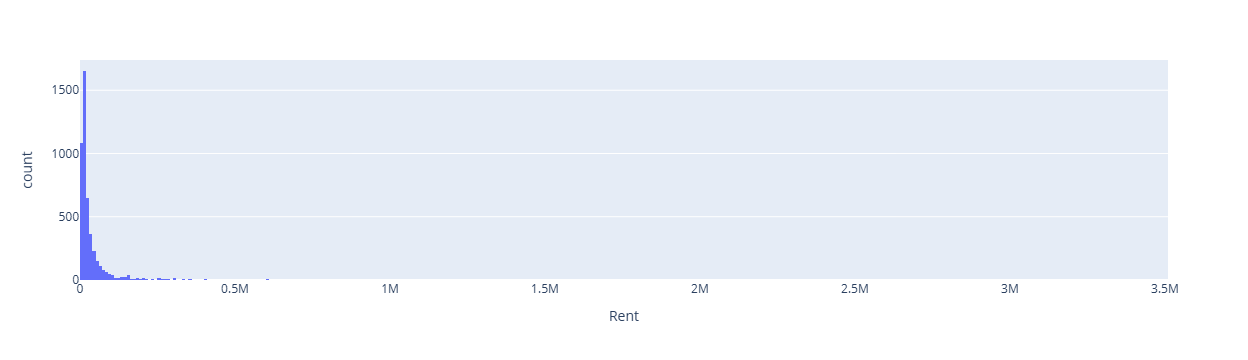

In [11]:
px.histogram(df, x="Rent")

In [12]:
Q1 = df["Rent"].quantile(0.25)
Q3 = df["Rent"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("Нижня межа:", lower)
print("Верхня межа:", upper)
print("Кількість викидів:", (df["Rent"] > upper).sum())
print("Усього рядків:", len(df))

Q1: 10000.0
Q3: 33000.0
Нижня межа: -24500.0
Верхня межа: 67500.0
Кількість викидів: 520
Усього рядків: 4746


In [13]:
df = df[df["Rent"] <= upper]
print(df.shape)

(4226, 12)


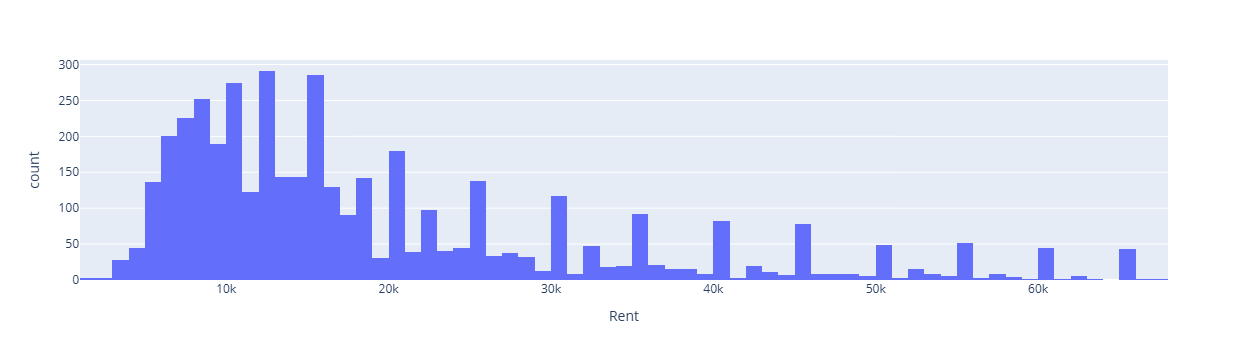

In [14]:
px.histogram(df, x="Rent")

In [15]:
df.select_dtypes(include="object").nunique()

Posted On              80
Floor                 340
Area Type               3
Area Locality        1997
City                    6
Furnishing Status       3
Tenant Preferred        3
Point of Contact        3
dtype: int64


## Завдання 3: Аналіз кореляцій та взаємозв'язків (3 бали)

**Що потрібно зробити:**
1. Обчисліть матрицю кореляцій для числових змінних
2. Візуалізуйте кореляційну матрицю за допомогою heatmap
3. Побудуйте scatter plot між Size та Rent
4. Проаналізуйте взаємозв'язок між BHK та Rent за допомогою boxplot (який розподіл плати для різних значень BHK)


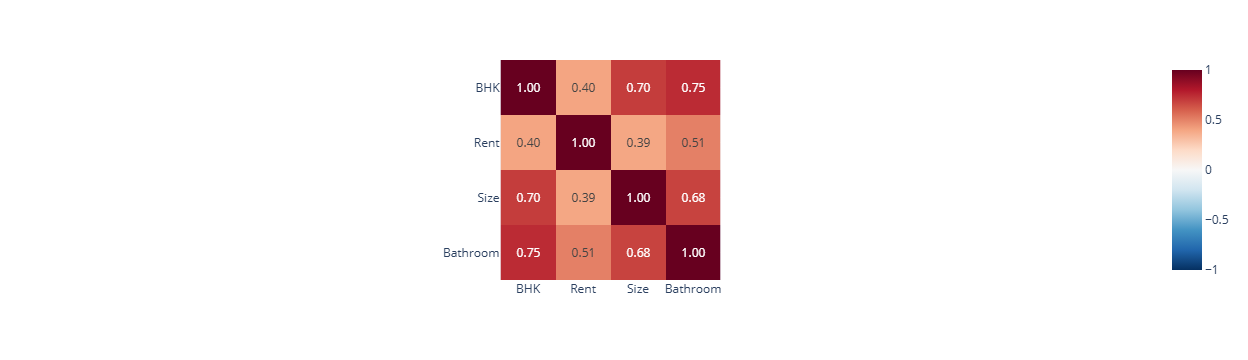

In [16]:
corr = df.corr(numeric_only=True)
px.imshow(corr, text_auto=".2f", color_continuous_scale="RdBu_r", zmin=-1, zmax=1)

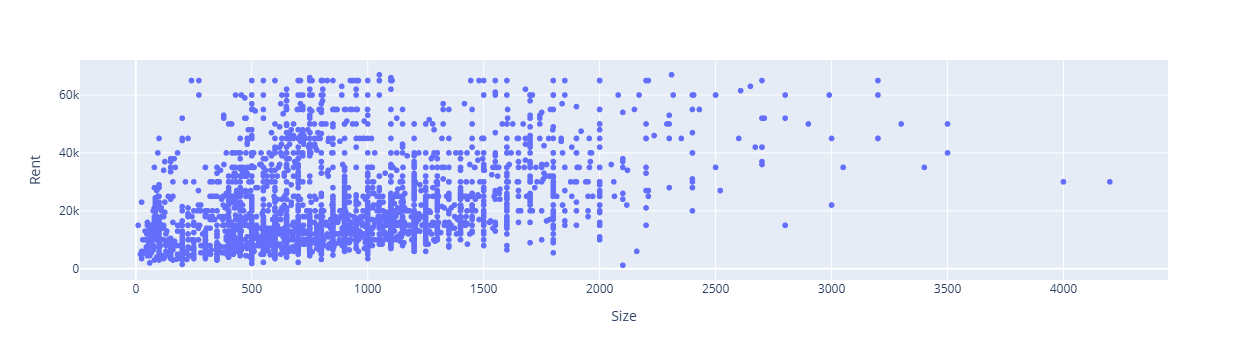

In [17]:
px.scatter(df, x="Size", y="Rent")

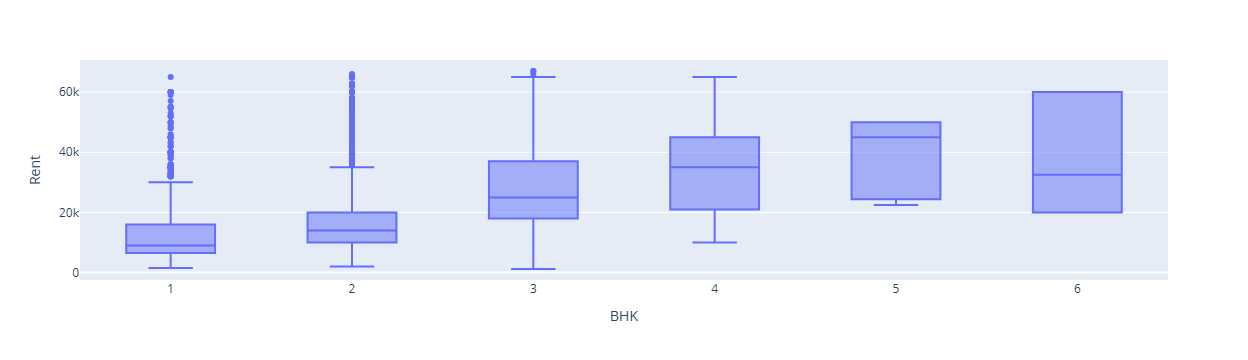

In [18]:
px.box(df, x="BHK", y="Rent")

**Scatter Size vs Rent**

Видно слабкий висхідний тренд: чим більша площа, тим вища ціна, але розкид величезний. Для площі 1000 кв. футів ціни можуть бути і 10 тис., і 60 тис. Це узгоджується з кореляцією 0.39: площа впливає, але не вирішальна. Є також кілька дивних точок: площа 3000–4000 кв. футів при ціні 15–30 тис. і дуже мала площа при високій ціні. Швидше за все, це помилки в даних або особливі випадки.

**Boxplot BHK vs Rent**

Ціна помітно росте з кількістю кімнат (медіана від ~9 тис. для 1 BHK до ~35–45 тис. для 4–5 BHK), але діапазони перетинаються: дорога квартира з 1–2 кімнатами коштує як звичайна з 3–4. Для 5 і 6 BHK оголошень мало, тому «коробки» неточні. Крапки над «вусами» в 1–2 BHK — це дорогі квартири, мабуть через район чи місто, а не через кімнати.

Головний висновок: самих BHK, Size і Bathroom не вистачить, тому в модель треба додати місто та інші категорії.

## Завдання 4: Feature Engineering та підготовка даних (4 бали)

**Що потрібно зробити:**
1. Закодуйте категоріальні змінні за допомогою One-Hot Encoding. Пригадайте, що в лекції ми говорили щодо кодування кат. змінних з великої кількістю різних значень і як працювати з такими випадками. Ви можете закодувати не всі кат. змінні, а лише ті, що вважаєте за потрібні (скажімо ті, що мають відносно небагато різних значень).
2. **Опціонально (по 0.5 бала за кожну доцільну ознаку):** Додайте нові ознаки, обчислені на основі наявних даних, які б на ваш погляд були корисними для моделі
3. Виберіть ознаки для побудови моделі (виключіть непотрібні колонки). Виключити можна, наприклад, ті колонки, які мають категоріальний тип і забагато (більше 20) різних значень. Треба виключити хоча б 1 колонку.
4. Розділіть дані на ознаки (X) та цільову змінну (y)
5. Застосуйте стандартизацію до числових ознак


In [19]:
cat_cols = ["Area Type", "City", "Furnishing Status", "Tenant Preferred", "Point of Contact"]

df_enc = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
df_enc = df_enc.drop(columns=["Area Locality", "Posted On"])

print(df_enc.shape)
df_enc.head()

(4226, 18)


,BHK,Rent,Size,Floor,Bathroom,Area Type_Carpet Area,Area Type_Super Area,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Builder,Point of Contact_Contact Owner
0,2,10000,1100,Ground out of 2,2,0,1,0,0,0,1,0,0,1,1,0,0,1
1,2,20000,800,1 out of 3,1,0,1,0,0,0,1,0,1,0,1,0,0,1
2,2,17000,1000,1 out of 3,1,0,1,0,0,0,1,0,1,0,1,0,0,1
3,2,10000,800,1 out of 2,1,0,1,0,0,0,1,0,0,1,1,0,0,1
4,2,7500,850,1 out of 2,1,1,0,0,0,0,1,0,0,1,0,0,0,1


In [20]:
parts = df_enc["Floor"].str.split(" out of ", expand=True)

floor_num = parts[0].replace({"Ground": 0, "Upper Basement": -1, "Lower Basement": -2})
df_enc["Floor_Number"] = pd.to_numeric(floor_num, errors="coerce")
df_enc["Total_Floors"] = pd.to_numeric(parts[1], errors="coerce")

df_enc = df_enc.drop(columns=["Floor"])

print(df_enc[["Floor_Number", "Total_Floors"]].isna().sum())
df_enc[["Floor_Number", "Total_Floors"]].head()

Floor_Number    0
Total_Floors    4
dtype: int64


,Floor_Number,Total_Floors
0,0,2.0
1,1,3.0
2,1,3.0
3,1,2.0
4,1,2.0


In [21]:
df_enc["Total_Floors"] = df_enc["Total_Floors"].fillna(df_enc["Total_Floors"].median())

X = df_enc.drop(columns=["Rent"])
y = df_enc["Rent"]

print(X.shape, y.shape)
print(X.isna().sum().sum())

(4226, 18) (4226,)
0


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train = X_train.copy()
X_test = X_test.copy()

num_cols = ["BHK", "Size", "Bathroom", "Floor_Number", "Total_Floors"]

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(X_train.shape, X_test.shape)
X_train[num_cols].describe().round(2)

(3380, 18) (846, 18)


,BHK,Size,Bathroom,Floor_Number,Total_Floors
count,3380.00,3380.00,3380.00,3380.00,3380.00
mean,-0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-1.29,-1.77,-1.15,-1.27,-0.71
25%,-1.29,-0.73,-1.15,-0.43,-0.55
50%,0.06,-0.15,0.27,-0.16,-0.23
75%,0.06,0.48,0.27,0.12,-0.07
max,5.44,6.91,7.38,12.70,10.06


## Завдання 5: Розділення даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на навчальну (80%) та тестову (20%) вибірки.
2. Створіть модель лінійної регресії.
3. Навчіть модель на навчальних даних.
4. Виведіть усі коефіцієнти моделі (ваги) та напишіть, які 2 ознаки найбільше впливають на прогноз.
5. Зробіть прогнози на тренувальній та тестовій вибірках.

In [25]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

coef = pd.DataFrame({"Ознака": X_train.columns, "Вага": model.coef_})
coef = coef.sort_values("Вага", key=abs, ascending=False)
print("Вільний член (intercept):", model.intercept_)
coef

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print(coef)
print(y_train_pred[:5])
print(y_test_pred[:5])

Вільний член (intercept): 29934.800684259637
                               Ознака          Вага
9                         City_Mumbai  16348.863620
15     Point of Contact_Contact Owner  -7926.841023
14   Point of Contact_Contact Builder  -4722.882253
11      Furnishing Status_Unfurnished  -4512.083962
1                                Size   3809.825536
10   Furnishing Status_Semi-Furnished  -3444.593593
8                        City_Kolkata  -2831.323655
0                                 BHK   2488.995275
7                      City_Hyderabad  -2476.640693
13            Tenant Preferred_Family  -2417.662152
6                          City_Delhi   2217.998633
4                Area Type_Super Area  -2197.213336
3               Area Type_Carpet Area  -1889.227504
17                       Total_Floors   1861.898335
2                            Bathroom   1688.427093
5                        City_Chennai  -1045.418859
12  Tenant Preferred_Bachelors/Family   -701.944630
16                 

**City_Mumbai (+16 349)**- квартира в Mumbai в середньому дорожча приблизно на 16 тис., ніж у базовому місті (Bangalore), за інших однакових умов.

**Point of Contact_Contact Owner (−7 927)**- якщо контактна особа — власник, оренда в середньому дешевша приблизно на 7.9 тис., ніж при контакті через агента (базова категорія).

## Завдання 6: Оцінка якості моделі (2 бали)

**Що потрібно зробити:**
1. Обчисліть MAE, RMSE та R² для навчальної та тестової вибірок
2. Порівняйте метрики та зробіть висновок про якість моделі
3. Проаналізуйте і дайте висновок, чи є ознаки перенавчання або недонавчання (**Нагадування**: перенавчання - коли модель дуже добре працює на тренувальних даних, але погано на тестових; недонавчання - коли модель погано працює навіть на тренувальних даних)
4. Побудуйте графік розсіювання "реальні vs прогнозовані значення" та зробіть висновок про якість моделі


        Train     Test
MAE   5432.84  5384.62
RMSE  7573.53  7558.60
R2       0.70     0.70


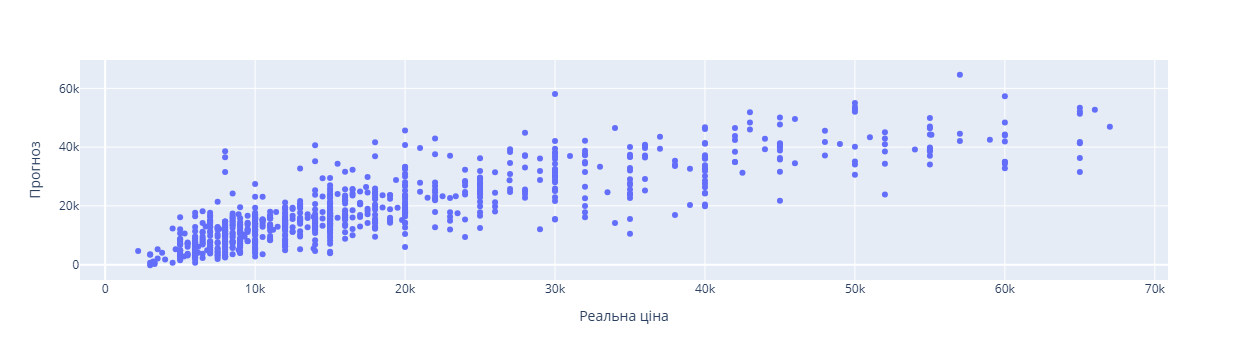

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

result = pd.DataFrame({
    "Train": metrics(y_train, y_train_pred),
    "Test": metrics(y_test, y_test_pred),
}).round(2)
print(result)

px.scatter(x=y_test, y=y_test_pred, labels={"x": "Реальна ціна", "y": "Прогноз"})

**R² = 0.70** означає, що модель пояснює приблизно 70% розкиду цін. Це непогано, але не ідеально.
**MAE ≈ 5 400** означає, що в середньому модель помиляється приблизно на 5.4 тис. Для оголошень із типовою ціною 10–20 тис. це відчутна похибка (приблизно третина).
**RMSE** більше за **MAE** (7.6 тис. проти 5.4 тис.): великі помилки трапляються, і саме вони підтягують RMSE.

Перенавчання немає. Метрики на train і test практично однакові: модель так само працює на нових даних, як і на тих, що бачила. Коли модель «вчить відповіді напам'ять», на test метрики були б помітно гіршими.
Є помірне недонавчання. Помилка досить велика навіть на train, тобто модель «не дотягує» до даних. Причина в тому, що лінійна регресія — проста модель, і ми дали їй обмежений набір ознак (без району).

**Графік «реальні vs прогнозовані»**

Ідеальний прогноз — це точки вздовж діагоналі. У нас точки йдуть уздовж неї, але з великим розкидом, тож зв'язок є. Для дорогих квартир (реальна ціна 40–65 тис.) прогноз часто нижчий за реальну ціну (точки під діагоналлю): модель недооцінює дороге житло. Для дешевого помітні випадки, де вона навпаки завищує прогноз.

## Завдання 7: Аналіз помилок (4 бали)

**Що потрібно зробити:**
1. Обчисліть помилки (residuals = реальні - прогнозовані значення)
2. Побудуйте гістограму розподілу помилок
3. Створіть scatter plot помилок відносно величини прогнозованих значень. Чи росте помилка з ростом прогнозованого значення?
4. Знайдіть 5 прогнозів з найбільшими помилками
5. Проаналізуйте, на яких типах житла модель помиляється найбільше. Типи можна розрізняти за кількістю кімнат чи містом, наприклад.
6. Подумайте і напишіть, які наступні кроки ви б зробили, аби поліпшити якість моделі. Опціонально можна їх зробити і ми перевіримо :)

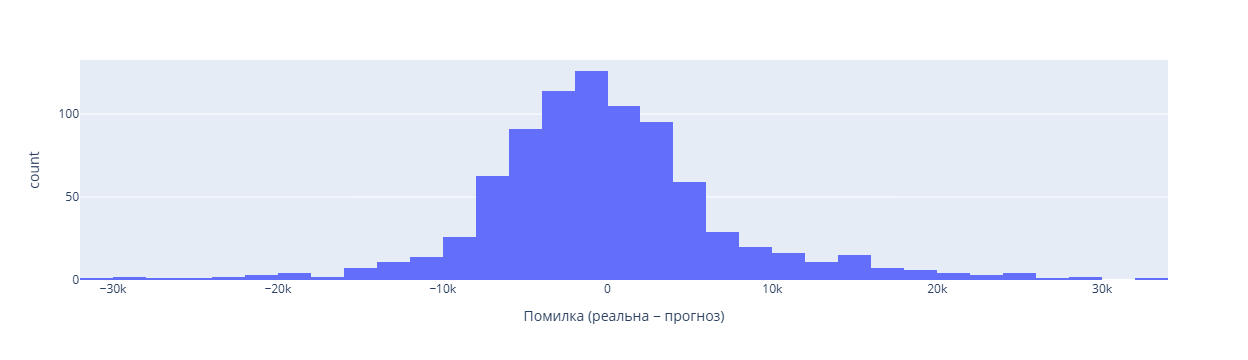

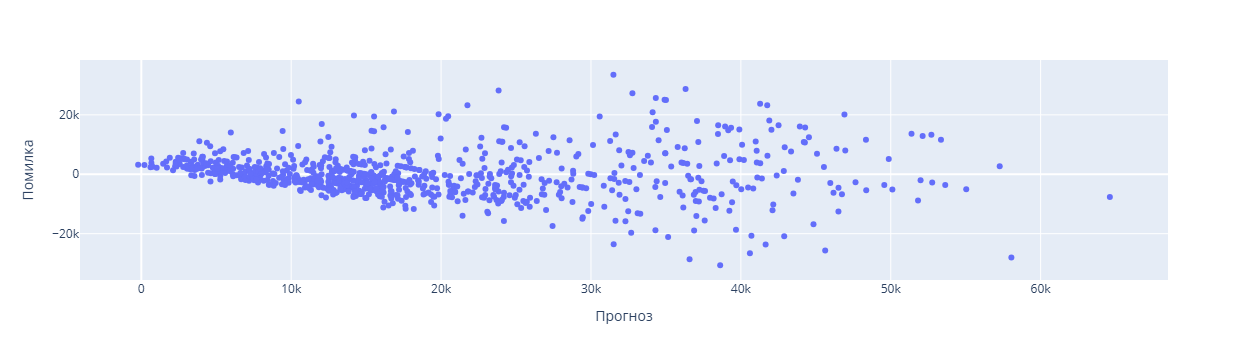

,Реальна,Прогноз,Помилка,Модуль помилки
3962,65000,31497.398434,33502.601566,33502.601566
549,8000,38619.238649,-30619.238649,30619.238649
3520,65000,36311.541280,28688.458720,28688.458720
904,8000,36577.958932,-28577.958932,28577.958932
2512,52000,23837.210667,28162.789333,28162.789333


In [27]:
residuals = y_test - y_test_pred

fig = px.histogram(x=residuals, nbins=50, labels={"x": "Помилка (реальна − прогноз)"})
fig.show()

fig = px.scatter(x=y_test_pred, y=residuals, labels={"x": "Прогноз", "y": "Помилка"})
fig.show()

errors = pd.DataFrame({
    "Реальна": y_test,
    "Прогноз": y_test_pred,
    "Помилка": residuals,
    "Модуль помилки": residuals.abs(),
})
errors.sort_values("Модуль помилки", ascending=False).head(5)

In [28]:
errors_full = errors.join(df[["City", "BHK", "Size"]])

print(errors_full.groupby("City")["Модуль помилки"].mean().round(0).sort_values(ascending=False))
print(errors_full.groupby("BHK")["Модуль помилки"].mean().round(0))

errors_full.sort_values("Модуль помилки", ascending=False).head(5)

City
Mumbai       9034.0
Delhi        7225.0
Chennai      4788.0
Hyderabad    4675.0
Kolkata      4070.0
Bangalore    3847.0
Name: Модуль помилки, dtype: float64
BHK
1     4357.0
2     4874.0
3     7688.0
4    11794.0
5     2766.0
6     7193.0
Name: Модуль помилки, dtype: float64


,Реальна,Прогноз,Помилка,Модуль помилки,City,BHK,Size
3962,65000,31497.398434,33502.601566,33502.601566,Hyderabad,3,1850
549,8000,38619.238649,-30619.238649,30619.238649,Mumbai,2,650
3520,65000,36311.541280,28688.458720,28688.458720,Chennai,3,1444
904,8000,36577.958932,-28577.958932,28577.958932,Mumbai,2,550
2512,52000,23837.210667,28162.789333,28162.789333,Delhi,2,1125


### Де модель помиляється найбільше

**За містами.** Середня абсолютна помилка найбільша в Mumbai (9 034) і Delhi (7 225), найменша в Bangalore (3 847).

**За кількістю кімнат.** Найбільша помилка для 4 BHK (11 794), далі 3 BHK (7 688) і 6 BHK (7 193). Для 1–2 BHK помилка становить 4–5 тис. Показник для 5 BHK (2 766) виглядає найкращим, але таких оголошень дуже мало, тому цьому числу не варто довіряти.

### Чому так

- У Mumbai і Delhi ціни сильно залежать від району (від дешевих околиць до центру). Ми виключили `Area Locality`, тому модель не знає, де саме розташована квартира, і для всього міста застосовує одну «середню» надбавку.
- Топ-5 найбільших помилок це підтверджує:
  - дві квартири в Mumbai (550–650 кв. футів) коштують 8 тис., а модель прогнозує ~37–38 тис., бо «Mumbai = дорого»;
  - дорогі квартири (3 BHK, 1850 і 1444 кв. футів у Hyderabad і Chennai, 65 тис.) модель недооцінює, бо за ознаками вони схожі на звичайні 3 BHK.
- Чим більша квартира, тим більший розкид цін, а таких оголошень мало, тому модель вчиться на них гірше.